In [26]:
from huggingface_hub import list_repo_files

files = list_repo_files("yandex/yambda", repo_type="dataset")
print([f for f in files if "50m" in f])

['flat/50m/dislikes.parquet', 'flat/50m/likes.parquet', 'flat/50m/listens.parquet', 'flat/50m/multi_event.parquet', 'flat/50m/undislikes.parquet', 'flat/50m/unlikes.parquet', 'sequential/50m/dislikes.parquet', 'sequential/50m/likes.parquet', 'sequential/50m/listens.parquet', 'sequential/50m/multi_event.parquet', 'sequential/50m/undislikes.parquet', 'sequential/50m/unlikes.parquet']


In [27]:
import pandas as pd
from huggingface_hub import hf_hub_download

path = hf_hub_download("yandex/yambda", "flat/50m/listens.parquet", repo_type="dataset")
listens = pd.read_parquet(path)
print(listens.shape)
print(listens.head())

(46467212, 6)
   uid  timestamp  item_id  is_organic  played_ratio_pct  track_length_seconds
0  100      39420  8326270           0               100                   170
1  100      39420  1441281           0               100                   105
2  100      39625   286361           0               100                   185
3  100      40110   732449           0               100                   240
4  100      40360  3397170           0                46                   130


In [28]:
print("Пользователей:", listens["uid"].nunique())
print("Треков:", listens["item_id"].nunique())
print("Событий:", len(listens))

Пользователей: 9238
Треков: 877168
Событий: 46467212


In [29]:
print("Min timestamp:", listens["timestamp"].min())
print("Max timestamp:", listens["timestamp"].max())

Min timestamp: 0
Max timestamp: 26000000


count     9238.000000
mean      5030.007794
std       5520.145410
min          6.000000
25%        937.250000
50%       3023.500000
75%       7182.000000
max      27617.000000
Name: count, dtype: float64
count    877168.000000
mean         52.974130
std         382.224045
min           1.000000
25%           1.000000
50%           3.000000
75%          12.000000
max       41984.000000
Name: count, dtype: float64


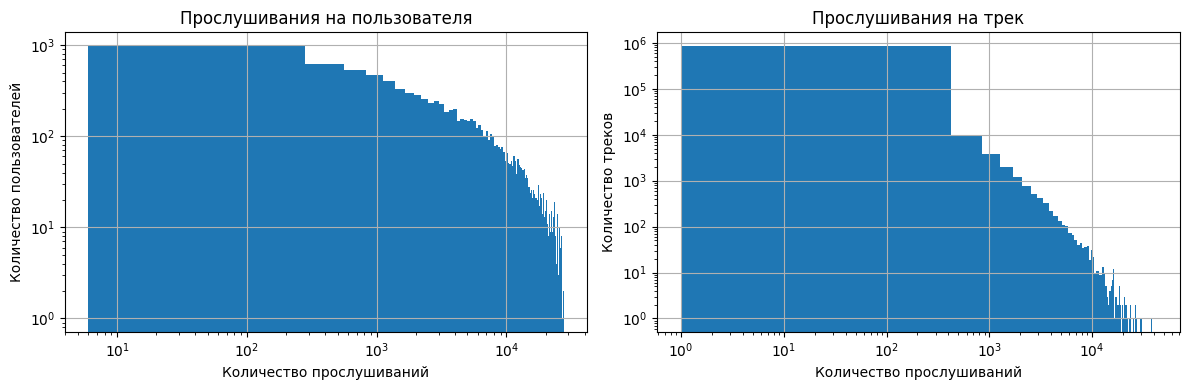

In [30]:
import matplotlib.pyplot as plt

# Сколько событий прослушивания у каждого пользователя
user_counts = listens["uid"].value_counts()

# Сколько событий приходится на каждый трек
track_counts = listens["item_id"].value_counts()

print(user_counts.describe())
print(track_counts.describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

user_counts.hist(bins=100, ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Прослушивания на пользователя")
axes[0].set_xlabel("Количество прослушиваний")
axes[0].set_ylabel("Количество пользователей")

track_counts.hist(bins=100, ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Прослушивания на трек")
axes[1].set_xlabel("Количество прослушиваний")
axes[1].set_ylabel("Количество треков")



plt.tight_layout()
plt.show()



In [31]:
organic_share = (listens["is_organic"] == 1).mean()
print(f"Доля органических прослушиваний: {organic_share:.2%}")

Доля органических прослушиваний: 51.66%


In [32]:
r = listens["played_ratio_pct"]

print("Прослушивание < 10%:", (r < 10).mean().round(4))
print("Прослушивание < 20%:", (r < 20).mean().round(4))
print("Полные прослушивания:", (r == 100).mean().round(4))
print("Пропуски:", r.isna().mean().round(4))

Прослушивание < 10%: 0.2663
Прослушивание < 20%: 0.3047
Полные прослушивания: 0.5323
Пропуски: 0.0


In [33]:
DAY = 86400          
GAP = 30 * 60

t_max = listens["timestamp"].max()
test_start = t_max - DAY
train_end  = test_start - GAP

# сигнал "понравилось": прослушано не менее 50% трека
a = listens["played_ratio_pct"] >= 50
pos = listens[a]

train = pos[pos["timestamp"] < train_end]
test  = pos[pos["timestamp"] >= test_start]

print(train.shape)
print(test.shape)




(29280230, 6)
(157696, 6)


Метрики Recall@k, NDCG@k

In [34]:
import numpy as np

def recall_at_k(recs, truth, k=100):
    # recs: dict uid -> список item_id по убыванию score
    # truth: dict uid -> set of item_id из теста
    scores = []
    for uid, t in truth.items():
        hits = len(set(recs.get(uid, [])[:k]) & t)
        scores.append(hits / len(t))
    return np.mean(scores)

def ndcg_at_k(recs, truth, k=100):
    scores = []
    for uid, t in truth.items():
        r = recs.get(uid, [])[:k]
        dcg = sum(1 / np.log2(i + 2) for i, it in enumerate(r) if it in t)
        idcg = sum(1 / np.log2(i + 2) for i in range(min(len(t), k)))
        scores.append(dcg / idcg)
    return np.mean(scores)

Первый baseline: Most Popular

In [35]:
truth = test.groupby("uid")["item_id"].apply(set).to_dict()
#Словарь вида uid -> {мн-во item_id, прослушанных треков}, из test
train_users = set(train["uid"])
#Доп проверка
truth = {u: s for u, s in truth.items() if u in train_users}

#top-100
top = train["item_id"].value_counts().index[:100].tolist()
#каждому пользователю рекомендуются просто top-100 треков oat
recs = {u: top for u in truth}

print("Recall@100:", recall_at_k(recs, truth))
print("NDCG@100:", ndcg_at_k(recs, truth))

Recall@100: 0.03529165514388649
NDCG@100: 0.023065267921339352


In [36]:
print("train_end:", train_end, "test_start:", test_start, "t_max:", t_max)
print("train:", train.shape, "test:", test.shape)
print("test users before filter:", test["uid"].nunique())
print("test users after filter:", len(truth))

train_end: 25911800 test_start: 25913600 t_max: 26000000
train: (29280230, 6) test: (157696, 6)
test users before filter: 4600
test users after filter: 4599


In [37]:
def split_at(pos, cutoff):
    train = pos[pos["timestamp"] < cutoff - GAP]
    target = pos[(pos["timestamp"] >= cutoff) & (pos["timestamp"] < cutoff + DAY)]
    truth = target.groupby("uid")["item_id"].apply(set).to_dict()
    users = set(train["uid"])
    truth = {u: s for u, s in truth.items() if u in users}
    return train, truth

def eval_popular(pos, cutoff, days=None, k=100):
    train, truth = split_at(pos, cutoff)
    if days is not None:
        train = train[train["timestamp"] >= cutoff - GAP - days * DAY]
    top = train["item_id"].value_counts().index[:k].tolist()
    recs = {u: top for u in truth}
    return recall_at_k(recs, truth, k), ndcg_at_k(recs, truth, k)

val_cutoff = test_start - DAY   # validation: сутки перед тестом

for days in [None, 1, 3, 7, 14, 30]:
    r, n = eval_popular(pos, val_cutoff, days)
    print(f"window={days}: recall={r:.4f}, ndcg={n:.4f}")

window=None: recall=0.0335, ndcg=0.0219
window=1: recall=0.0553, ndcg=0.0350
window=3: recall=0.0539, ndcg=0.0340
window=7: recall=0.0518, ndcg=0.0331
window=14: recall=0.0509, ndcg=0.0323
window=30: recall=0.0491, ndcg=0.0304


In [38]:
for days in [0.25, 0.5, 1, 3]:
    rs = []
    for shift in [1, 2, 3]:
        r, n = eval_popular(pos, test_start - shift * DAY, days)
        rs.append((r, n))
    print(days, np.mean(rs, axis=0))

best_days = 1  # подставь лучшее по усреднённым значениям
print("TEST:", eval_popular(pos, test_start, best_days))

0.25 [0.04686146 0.02697485]
0.5 [0.05279891 0.03337357]
1 [0.0538711  0.03385516]
3 [0.05344895 0.0339213 ]
TEST: (0.053126230199127614, 0.033015957036088055)


In [53]:
import scipy.sparse as sp
from implicit.als import AlternatingLeastSquares

#строит матрицу пользователи х треки, значение - кол-во прослушиваний
def build_matrix(train):
    uids = train["uid"].astype("category")
    iids = train["item_id"].astype("category")
    counts = train.groupby(["uid", "item_id"]).size().reset_index(name="n")
    u = counts["uid"].map({v: i for i, v in enumerate(uids.cat.categories)})
    i = counts["item_id"].map({v: j for j, v in enumerate(iids.cat.categories)})
    mat = sp.csr_matrix((counts["n"].astype("float32"), (u, i)),
                        shape=(len(uids.cat.categories), len(iids.cat.categories)))
    return mat, list(uids.cat.categories), list(iids.cat.categories)

#обучает и оценивает модель
def eval_als(pos, cutoff, factors=64, reg=0.01, iters=15, alpha=1.0, k=100):
    train, truth = split_at(pos, cutoff)
    seen = train.groupby("uid")["item_id"].apply(set).to_dict()
    truth_new = {u: t - seen[u] for u, t in truth.items()}
    truth_new = {u: t for u, t in truth_new.items() if t}

    mat, user_ids, item_ids = build_matrix(train)
    mat.data = 1 + alpha * mat.data
    model = AlternatingLeastSquares(factors=factors, regularization=reg,
                                iterations=iters, random_state=42)
    model.fit(mat)

    u_index = {u: i for i, u in enumerate(user_ids)}
    users = [u for u in truth_new if u in u_index]
    idx = np.array([u_index[u] for u in users])
    rec_idx, _ = model.recommend(idx, mat[idx], N=k, filter_already_liked_items=True)
    recs = {u: [item_ids[j] for j in row] for u, row in zip(users, rec_idx)}
    truth_new = {u: truth_new[u] for u in users}
    return recall_at_k(recs, truth_new, k), ndcg_at_k(recs, truth_new, k)

print(eval_als(pos, test_start - DAY))

#Важно! filter_already_liked_items=True значит что нельзя рекомендовать уже услышанные треки, False - можно

100%|██████████| 15/15 [00:25<00:00,  1.67s/it]


(0.06493387311228349, 0.028355939149641813)


In [54]:
import itertools, pandas as pd
#Перебор вариантов гиперпараметров(grid search)(ДОЛГО)
grid = {
    "factors": [32, 64, 128],
    "alpha":   [1, 10, 40],
    "reg":     [0.01, 0.1],
}

rows = []
for factors, alpha, reg in itertools.product(grid["factors"], grid["alpha"], grid["reg"]):
    rs = [eval_als(pos, test_start - s * DAY, factors=factors, reg=reg, alpha=alpha)
          for s in [1, 2, 3]]
    r, n = np.mean(rs, axis=0)
    rows.append(dict(factors=factors, alpha=alpha, reg=reg, recall=r, ndcg=n))
    print(rows[-1])          # печатаем по ходу, чтобы видеть прогресс

res = pd.DataFrame(rows).sort_values("ndcg", ascending=False)
res.to_csv("als_grid.csv", index=False)   # сохрани, чтобы не потерять при падении ядра
print(res.head(10))

100%|██████████| 15/15 [00:17<00:00,  1.15s/it]


{'factors': 32, 'alpha': 1, 'reg': 0.01, 'recall': 0.05723560850760739, 'ndcg': 0.02524988048622449}


100%|██████████| 15/15 [00:18<00:00,  1.24s/it]


{'factors': 32, 'alpha': 1, 'reg': 0.1, 'recall': 0.057170980575017745, 'ndcg': 0.025230061027632103}


100%|██████████| 15/15 [00:17<00:00,  1.16s/it]


...

100%|██████████| 15/15 [00:21<00:00,  1.41s/it]


{'factors': 64, 'alpha': 1, 'reg': 0.01, 'recall': 0.06375286560322561, 'ndcg': 0.027894920361262888}


100%|██████████| 15/15 [00:19<00:00,  1.32s/it]


{'factors': 64, 'alpha': 1, 'reg': 0.1, 'recall': 0.06395534367164808, 'ndcg': 0.027941631496268337}


100%|██████████| 15/15 [00:20<00:00,  1.37s/it]


In [40]:
def eval_my_top(pos, cutoff, k=100):
    train, truth = split_at(pos, cutoff)
    top = (train.groupby(["uid", "item_id"]).size().reset_index(name="n")
                .sort_values(["uid", "n"], ascending=[True, False]))
    recs = top.groupby("uid")["item_id"].apply(lambda s: s.tolist()[:k]).to_dict()
    return recall_at_k(recs, truth, k), ndcg_at_k(recs, truth, k)

print(eval_my_top(pos, test_start - DAY))

(0.2656124080862999, 0.17129101286304768)


In [41]:
#Популярное без повторов
def eval_popular_new(pos, cutoff, days=1, k=100):
    train, truth = split_at(pos, cutoff)
    seen = train.groupby("uid")["item_id"].apply(set).to_dict()
    truth_new = {u: t - seen[u] for u, t in truth.items()}
    truth_new = {u: t for u, t in truth_new.items() if t}
    recent = train[train["timestamp"] >= cutoff - GAP - days * DAY]
    top = recent["item_id"].value_counts().index[:1000].tolist()
    recs = {u: [i for i in top if i not in seen[u]][:k] for u in truth_new}
    return recall_at_k(recs, truth_new, k), ndcg_at_k(recs, truth_new, k)

print(eval_popular_new(pos, val_cutoff))

(0.06112916025923282, 0.03150654704855352)


In [42]:
# train, truth = split_at(pos, val_cutoff)
# seen = train.groupby("uid")["item_id"].apply(set).to_dict()

# n_all = sum(len(t) for t in truth.values())
# n_new = sum(len(t - seen[u]) for u, t in truth.items())
# print("доля повторов среди (user, track) в тесте:", 1 - n_new / n_all)

# truth_new = {u: t - seen[u] for u, t in truth.items()}
# truth_new = {u: t for u, t in truth_new.items() if t}
# print("пользователей с новыми треками:", len(truth_new), "из", len(truth))
pos["timestamp"] = pos["timestamp"].astype("int64")

In [48]:
def eval_my_top_decay(pos, cutoff, tau_days, k=100):
    train, truth = split_at(pos, cutoff)
    t_ref = float(cutoff - GAP)
    dt = t_ref - train["timestamp"].values.astype("float64")
    w = np.exp(-dt / (tau_days * DAY))
    assert w.max() <= 1.0 and np.isfinite(w).all()   # веса должны быть в (0, 1]
    s = (train[["uid", "item_id"]].assign(w=w)
              .groupby(["uid", "item_id"], as_index=False)["w"].sum()
              .sort_values(["uid", "w"], ascending=[True, False]))
    recs = s.groupby("uid")["item_id"].apply(lambda x: x.tolist()[:k]).to_dict()
    return recall_at_k(recs, truth, k), ndcg_at_k(recs, truth, k)



for tau in [0.5, 1, 3, 7, 14, 30, 100]:
    rs = [eval_my_top_decay(pos, test_start - s * DAY, tau) for s in [1, 2, 3]]
    print(tau, np.mean(rs, axis=0))

0.5 [0.29296521 0.21761437]
1 [0.2947135  0.22541001]
3 [0.30060434 0.23896407]
7 [0.31200862 0.24789831]
14 [0.3240258  0.24991761]
30 [0.33383554 0.24476941]
100 [0.31737794 0.21664069]


In [49]:
rs = [eval_my_top(pos, test_start - s * DAY) for s in [1, 2, 3]]
print(np.mean(rs, axis=0))

[0.26928964 0.17302183]
